## **Objective**
The bank marketing dataset contains customer information such as age, job, education, account balance, housing loan status, contact details, and previous campaign outcomes. The objective of this notebook is to build a LightGBM Classifier that predicts whether a customer will subscribe to a term deposit. In the target column, `0` represents a customer who did not subscribe, while `1` represents a customer who subscribed. An appropriate evaluation metric will be selected during model tuning based on the objective of the problem. Precision, accuracy, recall, F1-score, and ROC-AUC will be used to evaluate the baseline and tuned models. The training and testing performance of both models will also be compared to check for possible overfitting.

## **Import Libraries**

- Import the libraries required for data handling, visualisation, model building, tuning, and evaluation

In [1]:
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
from pathlib import Path
from lightgbm import LGBMClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve, accuracy_score)
from sklearn.model_selection import GridSearchCV, train_test_split, StratifiedKFold, cross_val_score
RANDOM_STATE = 42
FIG_DIR, MET_DIR = Path('../outputs/figures'), Path('../outputs/metrics')
FIG_DIR.mkdir(parents=True, exist_ok=True); MET_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

# **Understanding the Dataset**

## **Task 1**
- Load the bank marketing dataset and display the first few records of the dataset
- Check the column names and their data types
- Check for missing values

In [2]:
bank = pd.read_csv('../data/bank.csv')
display(bank.head())
print('Shape:', bank.shape, '| duplicate rows:', bank.duplicated().sum())
print('\nData types:\n', bank.dtypes.to_string())
print('\nMissing values per column:\n', bank.isna().sum().to_string())

,age,job,marital,education,default,balance,housing,loan,day,month,duration,campaign,pdays,previous,deposit
0,59,admin.,married,secondary,no,2343,yes,no,5,may,1042,1,-1,0,yes
1,56,admin.,married,secondary,no,45,no,no,5,may,1467,1,-1,0,yes
2,41,technician,married,secondary,no,1270,yes,no,5,may,1389,1,-1,0,yes
3,55,services,married,secondary,no,2476,yes,no,5,may,579,1,-1,0,yes
4,54,admin.,married,tertiary,no,184,no,no,5,may,673,2,-1,0,yes


Shape: (11162, 15) | duplicate rows: 0

Data types:
 age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
deposit        str

Missing values per column:
 age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
deposit      0


**Observation:** 11,162 customers, 14 predictors, and no missing values or duplicates. This version of the UCI Bank Marketing data has no `contact` or `poutcome` columns.

## **Task 2**
- Display the count of customers who subscribed and did not subscribe using readable labels
- Visualise the number of subscribed and not-subscribed customers using a bar plot

,Count,Share (%)
deposit,,
Not subscribed,5873,52.6
Subscribed,5289,47.4


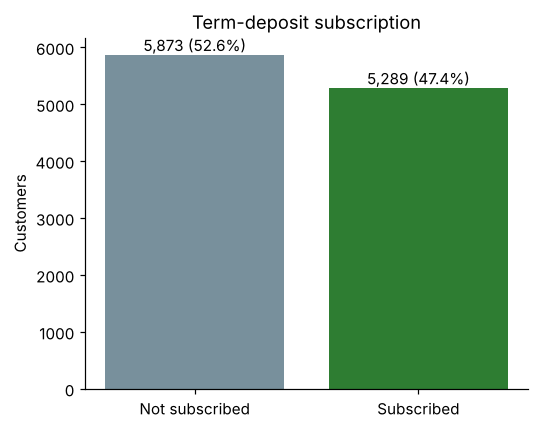

In [3]:
labels = bank['deposit'].map({'yes': 'Subscribed', 'no': 'Not subscribed'})
counts = labels.value_counts(); share = labels.value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({'Count': counts, 'Share (%)': share}))
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(counts.index, counts.values, color=['#78909C', '#2E7D32'])
ax.bar_label(bars, labels=[f'{c:,} ({s}%)' for c, s in zip(counts, share)])
ax.set_ylabel('Customers'); ax.set_title('Term-deposit subscription')
plt.tight_layout(); plt.savefig(FIG_DIR / 'class_distribution.png', bbox_inches='tight'); plt.show()

**Observation:** The classes are nearly balanced: 47.4% subscribed and 52.6% did not. This sample is balanced by design; real campaign response rates are far lower (around 11% in the full UCI dataset). Probabilities from this model therefore overstate real-world response rates.

# **Data Preparation**

## **Task 3**
- Convert the target labels into numerical values

In [4]:
bank['deposit'] = bank['deposit'].map({'no': 0, 'yes': 1})
print(bank['deposit'].value_counts().to_string())

deposit
0    5873
1    5289


## **Task 4**
- Separate the predictor features and target variable
- Create stratified training and testing sets

In [5]:
X = bank.drop(columns='deposit')
y = bank['deposit']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape} | Test: {X_test.shape} | subscription rate train/test: {y_train.mean():.3f} / {y_test.mean():.3f}')

Train: (8929, 14) | Test: (2233, 14) | subscription rate train/test: 0.474 / 0.474


## **Task 5**
- Encode the categorical training and testing features

In [6]:
CAT_COLS = X.select_dtypes(exclude='number').columns.tolist()
X_train_enc = pd.get_dummies(X_train, columns=CAT_COLS, drop_first=True, dtype=int)
X_test_enc = pd.get_dummies(X_test, columns=CAT_COLS, drop_first=True, dtype=int).reindex(columns=X_train_enc.columns, fill_value=0)
print('Categorical columns:', CAT_COLS)
print('Encoded feature count:', X_train_enc.shape[1])

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'month']
Encoded feature count: 36


# **Model Training**

## **Task 6**
- Train the baseline LightGBM model using the `n_estimators`, `learning_rate`, `random_state`, and `verbosity` parameters
- Generate training and testing predictions
- Evaluate the baseline model using confusion matrices, accuracy, precision, recall, F1-score, and ROC-AUC

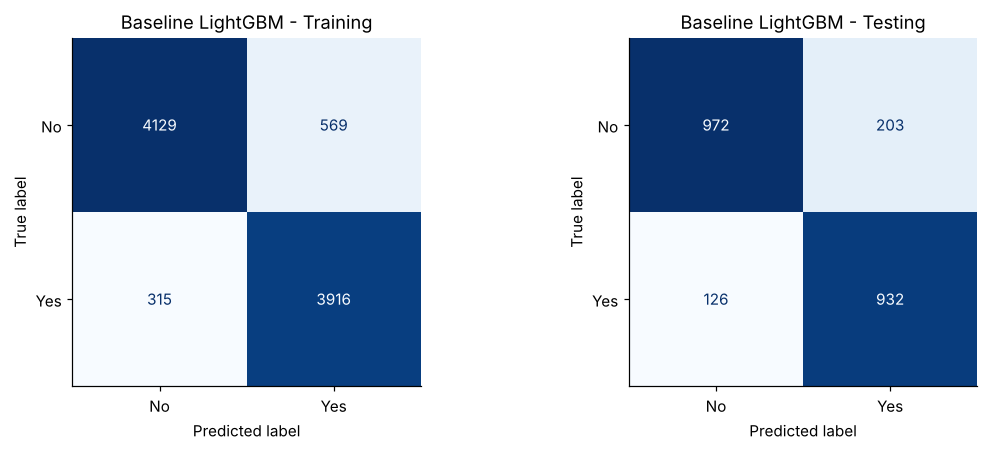

,Training,Testing
Accuracy,0.901,0.853
Precision,0.873,0.821
Recall,0.926,0.881
F1,0.899,0.850
ROC-AUC,0.969,0.922


In [7]:
def evaluate(y_true, y_pred, y_prob):
    return {'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred), 'F1': f1_score(y_true, y_pred), 'ROC-AUC': roc_auc_score(y_true, y_prob)}

def plot_cm_pair(name, tr_pred, te_pred, fname):
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
    for ax, (split, yt, yp) in zip(axes, [('Training', y_train, tr_pred), ('Testing', y_test, te_pred)]):
        ConfusionMatrixDisplay(confusion_matrix(yt, yp), display_labels=['No', 'Yes']).plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f'{name} - {split}')
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, bbox_inches='tight'); plt.show()

baseline = LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE, verbosity=-1)
baseline.fit(X_train_enc, y_train)
b_tr_pred, b_te_pred = baseline.predict(X_train_enc), baseline.predict(X_test_enc)
b_tr_prob, b_te_prob = baseline.predict_proba(X_train_enc)[:, 1], baseline.predict_proba(X_test_enc)[:, 1]
plot_cm_pair('Baseline LightGBM', b_tr_pred, b_te_pred, 'confusion_baseline.png')
base_metrics = pd.DataFrame({'Training': evaluate(y_train, b_tr_pred, b_tr_prob), 'Testing': evaluate(y_test, b_te_pred, b_te_prob)}).round(3)
display(base_metrics)

## **Task 7**
- Display all parameter values used by the baseline model
- Compare the training and testing values of the selected primary evaluation metric and calculate the performance gap to check for possible overfitting

In [8]:
print(pd.Series(baseline.get_params()).to_string())
# Primary metric: ROC-AUC. A campaign team uses the model to rank customers and call from the top
# of the list until its budget runs out, so the quality of the ranking matters more than any single
# threshold. Classes are nearly balanced (47% subscribed), so ROC-AUC is not distorted by imbalance.
PRIMARY = 'ROC-AUC'
base_gap = base_metrics.loc[PRIMARY, 'Training'] - base_metrics.loc[PRIMARY, 'Testing']
print(f'\nBaseline ROC-AUC: train = {base_metrics.loc[PRIMARY, "Training"]:.3f}, test = {base_metrics.loc[PRIMARY, "Testing"]:.3f}, gap = {base_gap:.3f}')

boosting_type          gbdt
class_weight           None
colsample_bytree        1.0
importance_type       split
learning_rate           0.1
max_depth                -1
min_child_samples        20
min_child_weight      0.001
min_split_gain          0.0
n_estimators            100
n_jobs                 None
num_leaves               31
objective              None
random_state             42
reg_alpha               0.0
reg_lambda              0.0
subsample               1.0
subsample_for_bin    200000
subsample_freq            0
verbosity                -1

Baseline ROC-AUC: train = 0.969, test = 0.922, gap = 0.047


**Observation:** The baseline (100 trees, 31 leaves, learning rate 0.1) reaches a test ROC-AUC of 0.922, with a modest train-test gap of 0.047.

**Primary metric: ROC-AUC.** A campaign team uses the model to rank customers and calls from the top of the list until the budget runs out, so the quality of the ranking matters more than any single threshold.

## **Task 8**
- Display sample customers with their actual and baseline predicted deposit labels

In [9]:
lab = {0: 'No', 1: 'Yes'}
idx = X_test.sample(8, random_state=RANDOM_STATE).index
samples = X_test.loc[idx, ['age', 'job', 'balance', 'housing', 'month', 'duration', 'campaign']].copy()
samples['Actual'] = y_test.loc[idx].map(lab)
samples['Baseline predicted'] = pd.Series(b_te_pred, index=X_test.index).loc[idx].map(lab)
samples['P(yes)'] = pd.Series(b_te_prob, index=X_test.index).loc[idx].round(2)
display(samples)

,age,job,balance,housing,month,duration,campaign,Actual,Baseline predicted,P(yes)
7132,34,blue-collar,1125,yes,nov,141,2,No,No,0.04
1996,42,services,146,yes,may,670,4,Yes,Yes,0.76
1189,53,management,1624,no,feb,158,3,Yes,No,0.29
7445,33,services,406,yes,feb,61,1,No,No,0.02
7979,34,technician,484,no,may,84,4,No,No,0.01
10388,35,admin.,11,yes,jul,103,4,No,No,0.02
4230,37,management,57,no,feb,345,1,Yes,No,0.33
10579,38,admin.,4023,no,jun,339,2,No,No,0.47


## **Task 9**
- Display the top five most important features of the baseline LightGBM model

,Share of total gain
duration,0.414
pdays,0.122
day,0.080
housing_yes,0.062
age,0.056


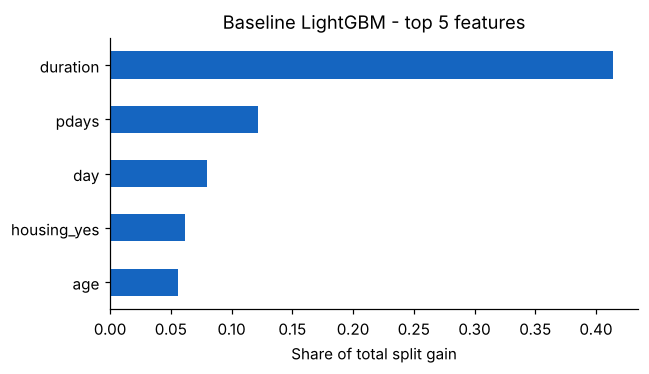

In [10]:
imp = pd.Series(baseline.booster_.feature_importance(importance_type='gain'), index=X_train_enc.columns)
imp = (imp / imp.sum()).sort_values(ascending=False)
display(imp.head(5).round(3).to_frame('Share of total gain'))
fig, ax = plt.subplots(figsize=(6, 3.5))
imp.head(5)[::-1].plot.barh(ax=ax, color='#1565C0'); ax.set_xlabel('Share of total split gain')
ax.set_title('Baseline LightGBM - top 5 features')
plt.tight_layout(); plt.savefig(FIG_DIR / 'feature_importance_baseline.png', bbox_inches='tight'); plt.show()

**Observation:** `duration` (call length in seconds) accounts for 41% of the total split gain, more than the next four features combined. That is a warning sign, examined in Extension A.

# **Hyperparameter Tuning**

## **Task 10**
- Define suitable values for the `n_estimators`, `learning_rate`, `num_leaves`, `max_depth`, and `min_child_samples` parameters to be tested during LightGBM model tuning


In [11]:
param_grid = {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1], 'num_leaves': [15, 31, 63],
              'max_depth': [-1, 6], 'min_child_samples': [20, 50]}
print(int(np.prod([len(v) for v in param_grid.values()])), 'combinations x 5 folds')

48 combinations x 5 folds


## **Task 11**
- Select an appropriate scoring metric according to the problem statement and model objective
- Tune the LightGBM model using five-fold cross-validation and the selected scoring metric
- Display the best hyperparameters, best cross-validation score, and best trained model selected by `GridSearchCV`

In [12]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(LGBMClassifier(random_state=RANDOM_STATE, verbosity=-1, n_jobs=1), param_grid,
                    scoring='roc_auc', cv=cv5, n_jobs=-1)
grid.fit(X_train_enc, y_train)
print('Best hyperparameters:', grid.best_params_)
print(f'Best 5-fold CV ROC-AUC: {grid.best_score_:.4f}')
print('Best model:', grid.best_estimator_)

Best hyperparameters: {'learning_rate': 0.1, 'max_depth': -1, 'min_child_samples': 20, 'n_estimators': 100, 'num_leaves': 31}
Best 5-fold CV ROC-AUC: 0.9168
Best model: LGBMClassifier(n_jobs=1, random_state=42, verbosity=-1)


**Observation:** Across 48 combinations, the best CV ROC-AUC (0.917) comes from **exactly the default settings** (100 trees, learning rate 0.1, 31 leaves, no depth limit, 20 minimum samples per leaf). The grid confirms the defaults rather than improving on them.

# **Tuned Model Evaluation and Interpretation**

## **Task 12**
- Store the best tuned LightGBM model and generate predictions and probability scores for the training and testing datasets
- Compare the training and testing values of the selected primary evaluation metric and calculate the performance gap

In [13]:
tuned = grid.best_estimator_
t_tr_pred, t_te_pred = tuned.predict(X_train_enc), tuned.predict(X_test_enc)
t_tr_prob, t_te_prob = tuned.predict_proba(X_train_enc)[:, 1], tuned.predict_proba(X_test_enc)[:, 1]
tuned_metrics = pd.DataFrame({'Training': evaluate(y_train, t_tr_pred, t_tr_prob), 'Testing': evaluate(y_test, t_te_pred, t_te_prob)}).round(3)
tuned_gap = tuned_metrics.loc[PRIMARY, 'Training'] - tuned_metrics.loc[PRIMARY, 'Testing']
print(f'Tuned ROC-AUC: train = {tuned_metrics.loc[PRIMARY, "Training"]:.3f}, test = {tuned_metrics.loc[PRIMARY, "Testing"]:.3f}, gap = {tuned_gap:.3f}')

Tuned ROC-AUC: train = 0.969, test = 0.922, gap = 0.047


**Observation:** Because the selected model is the baseline configuration, all metrics are identical: test ROC-AUC 0.922, train-test gap 0.047.

## **Task 13**
- Display sample customers with their actual deposit labels and the labels predicted by the tuned model

In [14]:
samples_t = samples.drop(columns=['Baseline predicted', 'P(yes)']).copy()
samples_t['Tuned predicted'] = pd.Series(t_te_pred, index=X_test.index).loc[idx].map(lab)
samples_t['P(yes)'] = pd.Series(t_te_prob, index=X_test.index).loc[idx].round(2)
display(samples_t)

,age,job,balance,housing,month,duration,campaign,Actual,Tuned predicted,P(yes)
7132,34,blue-collar,1125,yes,nov,141,2,No,No,0.04
1996,42,services,146,yes,may,670,4,Yes,Yes,0.76
1189,53,management,1624,no,feb,158,3,Yes,No,0.29
7445,33,services,406,yes,feb,61,1,No,No,0.02
7979,34,technician,484,no,may,84,4,No,No,0.01
10388,35,admin.,11,yes,jul,103,4,No,No,0.02
4230,37,management,57,no,feb,345,1,Yes,No,0.33
10579,38,admin.,4023,no,jun,339,2,No,No,0.47


## **Task 14**
- Create confusion matrices to compare the actual and predicted classes for the tuned model’s training and testing sets

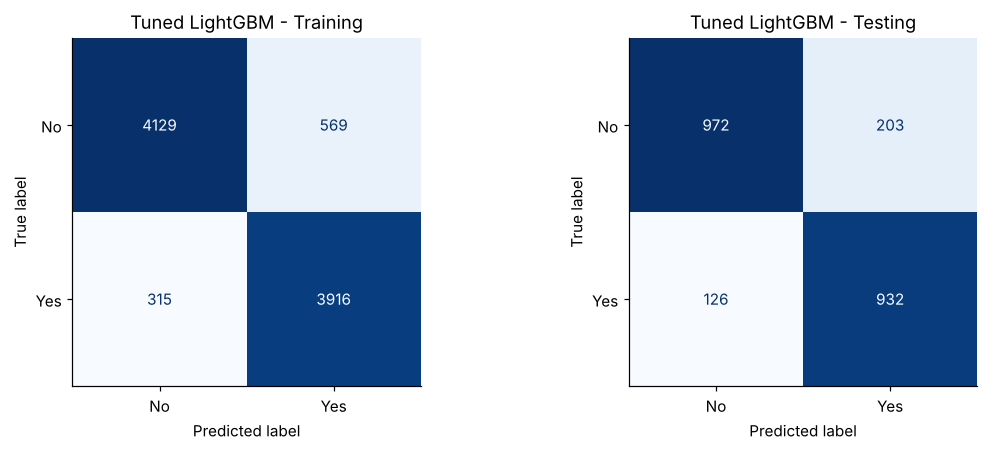

In [15]:
plot_cm_pair('Tuned LightGBM', t_tr_pred, t_te_pred, 'confusion_tuned.png')

## **Task 15**
- Evaluate the tuned LightGBM model using accuracy, precision, recall, F1-score, and ROC-AUC

In [16]:
display(tuned_metrics)

,Training,Testing
Accuracy,0.901,0.853
Precision,0.873,0.821
Recall,0.926,0.881
F1,0.899,0.850
ROC-AUC,0.969,0.922


## **Task 16**
- Plot the training and testing ROC curves for the baseline and tuned LightGBM models

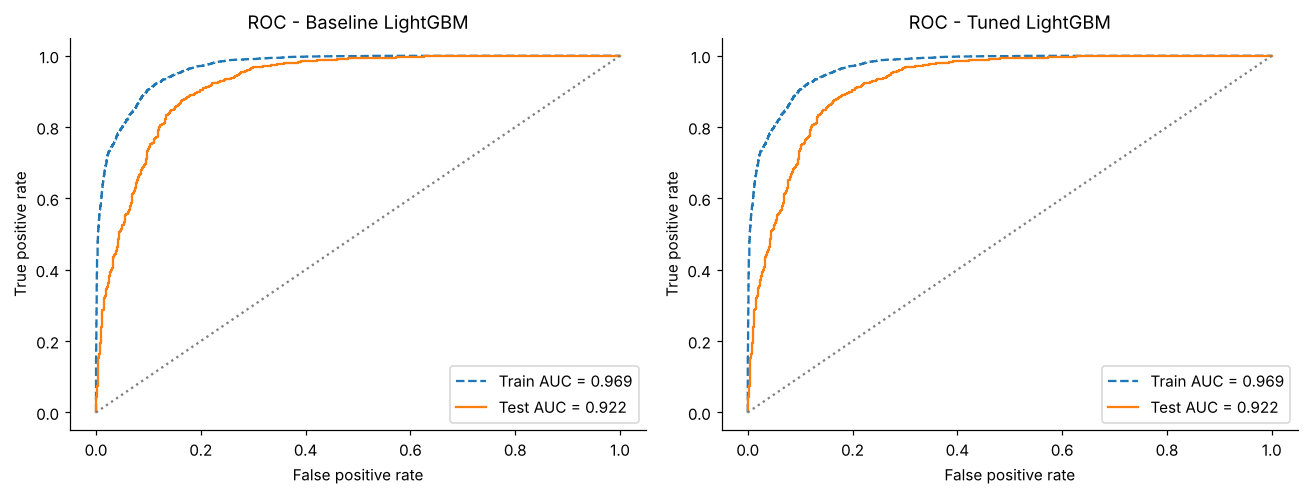

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (name, trp, tep) in zip(axes, [('Baseline', b_tr_prob, b_te_prob), ('Tuned', t_tr_prob, t_te_prob)]):
    for split, yt, pp, ls in [('Train', y_train, trp, '--'), ('Test', y_test, tep, '-')]:
        fpr, tpr, _ = roc_curve(yt, pp); ax.plot(fpr, tpr, ls, label=f'{split} AUC = {roc_auc_score(yt, pp):.3f}')
    ax.plot([0, 1], [0, 1], ':', color='grey'); ax.set_title(f'ROC - {name} LightGBM')
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(FIG_DIR / 'roc_curves.png', bbox_inches='tight'); plt.show()

## **Task 17**
- Compare the baseline and tuned LightGBM models using accuracy, precision, recall, F1-score, and ROC-AUC, along with the training and testing score gap of the selected metric



In [18]:
comparison = pd.DataFrame({'Baseline - Train': base_metrics['Training'], 'Baseline - Test': base_metrics['Testing'],
                           'Tuned - Train': tuned_metrics['Training'], 'Tuned - Test': tuned_metrics['Testing']})
comparison.loc['ROC-AUC train-test gap'] = [base_gap, np.nan, tuned_gap, np.nan]
display(comparison.round(3))
comparison.round(4).to_csv(MET_DIR / 'baseline_vs_tuned.csv')

,Baseline - Train,Baseline - Test,Tuned - Train,Tuned - Test
Accuracy,0.901,0.853,0.901,0.853
Precision,0.873,0.821,0.873,0.821
Recall,0.926,0.881,0.926,0.881
F1,0.899,0.850,0.899,0.850
ROC-AUC,0.969,0.922,0.969,0.922
ROC-AUC train-test gap,0.047,NaN,0.047,NaN


**Observation:** Baseline and tuned models are the same model. For this dataset, LightGBM's defaults were already well suited, and the honest conclusion is that tuning added nothing.

# Extensions Beyond the Exercise
## A. The `duration` leak
`duration` is the length of the sales call in seconds. It is only known **after** the call has ended, by which time the outcome is also known. The dataset's original authors (Moro et al., UCI) note that it should be dropped if the goal is a realistic predictive model. The tuned configuration is refitted without it.

In [19]:
print('Median call duration (s): subscribed =', int(bank.loc[bank.deposit == 1, 'duration'].median()),
      '| not subscribed =', int(bank.loc[bank.deposit == 0, 'duration'].median()))
Xtr_nd, Xte_nd = X_train_enc.drop(columns='duration'), X_test_enc.drop(columns='duration')
grid_nd = GridSearchCV(LGBMClassifier(random_state=RANDOM_STATE, verbosity=-1, n_jobs=1), param_grid,
                       scoring='roc_auc', cv=cv5, n_jobs=-1).fit(Xtr_nd, y_train)
nd = grid_nd.best_estimator_
nd_prob = nd.predict_proba(Xte_nd)[:, 1]; nd_pred = nd.predict(Xte_nd)
print('Best hyperparameters without duration:', grid_nd.best_params_, f'| CV ROC-AUC {grid_nd.best_score_:.4f}')
leak = pd.DataFrame({'Tuned, with duration': tuned_metrics['Testing'],
                     'Tuned, without duration': pd.Series(evaluate(y_test, nd_pred, nd_prob)).round(3)})
display(leak)
leak.to_csv(MET_DIR / 'duration_leak_comparison.csv')
imp_nd = pd.Series(nd.booster_.feature_importance(importance_type='gain'), index=Xtr_nd.columns)
display((imp_nd / imp_nd.sum()).sort_values(ascending=False).head(6).round(3).to_frame('Share of gain (no duration)'))

Median call duration (s): subscribed = 426 | not subscribed = 163


Best hyperparameters without duration: {'learning_rate': 0.05, 'max_depth': 6, 'min_child_samples': 20, 'n_estimators': 300, 'num_leaves': 15} | CV ROC-AUC 0.7727


,"Tuned, with duration","Tuned, without duration"
Accuracy,0.853,0.724
Precision,0.821,0.765
Recall,0.881,0.601
F1,0.850,0.673
ROC-AUC,0.922,0.774


,Share of gain (no duration)
pdays,0.221
day,0.129
age,0.118
housing_yes,0.103
balance,0.101
campaign,0.041


**Observation:** Subscribers' calls last a median of 426 seconds, against 163 for non-subscribers. Call length is a *consequence* of interest, not something known before calling. Without `duration`, the re-tuned model's test ROC-AUC falls from **0.922 to 0.774**, and recall falls from 0.881 to 0.601. The 0.92 figure describes a model that cannot be used before a call is made. Without duration, the most useful features are days since the last contact (`pdays`), day of month, age, housing-loan status and account balance.

## B. What the realistic model is worth to a campaign
Customers in the test set are ranked by the no-duration model's predicted probability. The cumulative gains curve shows what share of all subscribers is reached by calling the top X% of the list.

,Share of list called,Share of subscribers reached,Lift vs random,Hit rate in called group
0,0.1,0.194,1.938,0.919
1,0.2,0.368,1.838,0.872
2,0.3,0.519,1.730,0.821
3,0.5,0.703,1.406,0.667


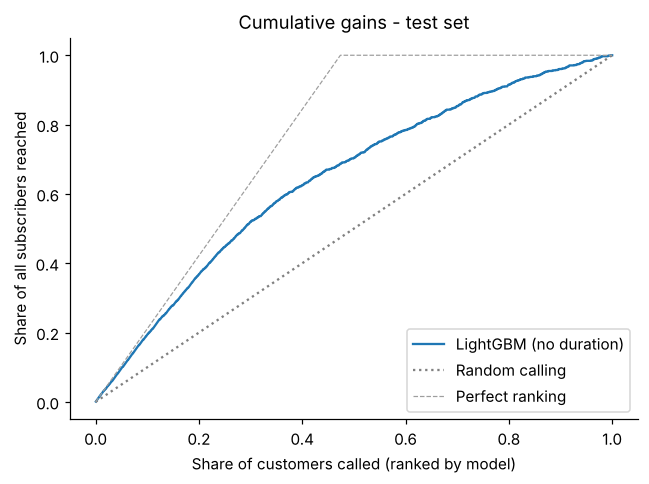

In [20]:
order = np.argsort(-nd_prob)
cum_yes = np.cumsum(y_test.values[order]) / y_test.sum()
pct_called = np.arange(1, len(order) + 1) / len(order)
gains = pd.DataFrame({'Share of list called': [0.1, 0.2, 0.3, 0.5],
                      'Share of subscribers reached': [cum_yes[int(p * len(order)) - 1] for p in [0.1, 0.2, 0.3, 0.5]]})
gains['Lift vs random'] = gains['Share of subscribers reached'] / gains['Share of list called']
gains['Hit rate in called group'] = [y_test.values[order][:int(p * len(order))].mean() for p in gains['Share of list called']]
display(gains.round(3))
gains.round(4).to_csv(MET_DIR / 'cumulative_gains_no_duration.csv', index=False)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(pct_called, cum_yes, label='LightGBM (no duration)'); ax.plot([0, 1], [0, 1], ':', color='grey', label='Random calling')
ax.plot([0, y_test.mean(), 1], [0, 1, 1], '--', color='#9E9E9E', lw=0.8, label='Perfect ranking')
ax.set_xlabel('Share of customers called (ranked by model)'); ax.set_ylabel('Share of all subscribers reached')
ax.set_title('Cumulative gains - test set'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(FIG_DIR / 'cumulative_gains.png', bbox_inches='tight'); plt.show()

**Observation:** Even at an AUC of 0.774, the realistic model is useful for prioritisation. Calling the top 10% of the ranked list reaches 19.4% of all subscribers (1.9x lift), with a 92% hit rate in that group. The top 30% reaches 51.9% of subscribers, with an 82% hit rate. Hit rates are inflated by this sample's 47% base rate, so in a real campaign the lift is the more transferable number.

# Conclusion

| Test set | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Baseline = tuned (with `duration`) | 0.853 | 0.821 | 0.881 | 0.850 | 0.922 |
| Tuned, **without** `duration` | 0.724 | 0.765 | 0.601 | 0.673 | 0.774 |

**Findings**
1. LightGBM's default configuration was already the best in the grid. Tuning confirmed it rather than improving it.
2. Most of the headline performance comes from `duration`, a variable that only exists after the call. Removing it gives a realistic ROC-AUC of 0.77.
3. The realistic model still roughly doubles the hit rate for the first 10-20% of calls, which is how it would actually be used.

**Limitations:** A balanced sample (47% positive) unlike real campaigns, so probabilities need recalibrating before use. There is no time ordering, and `day`/`month` may partly encode campaign timing. Gain-based importance is not causal.